## 1. Загрузка и описание данных

**UCI Online Retail**: покупки в британском интернет-магазине с 1 декабря 2010 года по 9 декабря 2011 года.
[Первоисточник](https://archive.ics.uci.edu/dataset/352/online+retail)

Данные получаем из [ZIP-архива UCI](https://archive.ics.uci.edu/static/public/352/online+retail.zip).
Функция `load_raw()` скачивает архив, проверяет SHA-256, извлекает `Online Retail.xlsx`
и читает его через `pandas.read_excel`. При повторном запуске используется скачанный архив.

**Запуск:** Python 3.12. Из каталога `hw1` выполнить `python -m pip install -r requirements.txt`,
открыть `experiments.ipynb` в Jupyter или VS Code, выбрать это окружение и выполнить все ячейки по порядку.
Данные сохраняются в `data/raw/`.

Одна исходная строка — товарная позиция счёта. Покупка того же товара в другом счёте является новым событием.
Исходный объём: **541 909 строк, 4 372 известных покупателя, 4 070 кодов товаров**.
Итоговая выборка после очистки и фильтрации из раздела 2:
**326 661 покупка, 3 076 покупателей, 2 761 товар**, 213 720 уникальных пар покупатель–товар.

| Поле | Смысл |
|---|---|
| `CustomerID` | Идентификатор покупателя |
| `StockCode` | Код товара |
| `InvoiceNo` | Номер счёта; префикс `C` означает отмену |
| `InvoiceDate` | Дата и время операции |
| `Quantity` | Количество единиц товара |
| `UnitPrice` | Цена единицы товара в GBP |
| `Description` | Название товара |
| `Country` | Страна покупателя |

Рекомендуем **десять ранее не купленных пользователем товаров**.
Релевантным считаем товар, для которого в будущем окне зарегистрирована хотя бы одна покупка
с положительными ценой и количеством. Это бинарный критерий для всех пяти моделей;
количество единиц и обучающий таргет его не меняют.


In [1]:
import gc
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
from models.utils import (load_raw, clean_data, interaction_matrices, history_bundle, train_model,
                          prepare_evaluation, evaluate)

SEED = 42
np.random.seed(SEED)
thread_limit = threadpool_limits(limits=2)
pd.set_option('display.max_colwidth', 180)
pd.set_option('display.max_columns', 12)

raw = load_raw()
display(raw.head())


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. EDA и подготовка

Удаляем точные дубликаты, строки без ID или даты, отмены, операции с неположительными
ценой или количеством. Для товарных кодов оставляем пять цифр и необязательную латинскую букву:
так исключаются почтовые услуги, комиссии и ручные корректировки.
Пропущенные названия и страны заменяем на `UNKNOWN`. Продажу не удаляем задним числом
по возврату, произошедшему в будущем.

Для устойчивого обучения используем итеративный 5-core: не менее пяти разных товаров
на пользователя и пяти разных покупателей на товар. Отбор определяется только историей
до начала validation; будущие покупки не влияют на состав пользователей и каталога.
Случайное сокращение данных не требуется.


In [2]:
display(pd.DataFrame({'пропуски': raw.isna().sum(), 'доля': raw.isna().mean()}))
print('Точные дубликаты:', raw.duplicated().sum())
clean, cleaning = clean_data(raw)
display(pd.DataFrame(cleaning['cleaning_steps']))

VALIDATION_START = pd.Timestamp('2011-09-01')
TEST_START = pd.Timestamp('2011-10-15')
MIN_USER_ITEMS = 5
MIN_ITEM_USERS = 5
past = clean.loc[clean.InvoiceDate < VALIDATION_START].copy()
core = past.copy()
while True:
    before = len(core)
    counts = core.groupby('CustomerID').StockCode.nunique()
    core = core.loc[core.CustomerID.isin(counts[counts >= MIN_USER_ITEMS].index)]
    counts = core.groupby('StockCode').CustomerID.nunique()
    core = core.loc[core.StockCode.isin(counts[counts >= MIN_ITEM_USERS].index)]
    if len(core) == before:
        break
user_ids = sorted(core.CustomerID.unique())
item_ids = sorted(core.StockCode.unique())
umap = dict(zip(user_ids, range(len(user_ids))))
imap = dict(zip(item_ids, range(len(item_ids))))
retained = clean.loc[clean.CustomerID.isin(umap) & clean.StockCode.isin(imap)].copy()
retained['u'] = retained.CustomerID.map(umap).astype('int64')
retained['i'] = retained.StockCode.map(imap).astype('int64')
shape = (len(user_ids), len(item_ids))
assert 100_000 <= len(retained) <= 2_000_000
assert min(shape) >= 1000

sparsity_rows = []
for name, frame in [('После очистки', clean), ('После 5-core', retained)]:
    pairs = len(frame.drop_duplicates(['CustomerID', 'StockCode']))
    sparsity_rows.append({'выборка': name,
                         'разреженность': 1 - pairs / (frame.CustomerID.nunique() * frame.StockCode.nunique())})
display(pd.DataFrame(sparsity_rows))
assert (len(retained), *shape) == (326661, 3076, 2761)
assert len(retained.drop_duplicates(['u', 'i'])) == 213720


Точные дубликаты: 5268


,пропуски,доля
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,1454,0.002683
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,135080,0.249267
Country,0,0.000000


,step,removed,remaining
0,exact_duplicates,5268,536641
1,missing_keys,135037,401604
2,cancellations,8872,392732
3,nonpositive_quantity_or_price,40,392692
4,nonstandard_stock_codes,1833,390859


,выборка,разреженность
0,После очистки,0.983217
1,После 5-core,0.974835


Активность, популярность и метаданные анализируем на доступной истории после 5-core.
Календарная гистограмма описывает весь корпус; декабрь 2011 года представлен не полностью.


Доля покупателей UK: 0.8972691807542262
Доля товаров с несколькими названиями: 0.04961970300615719


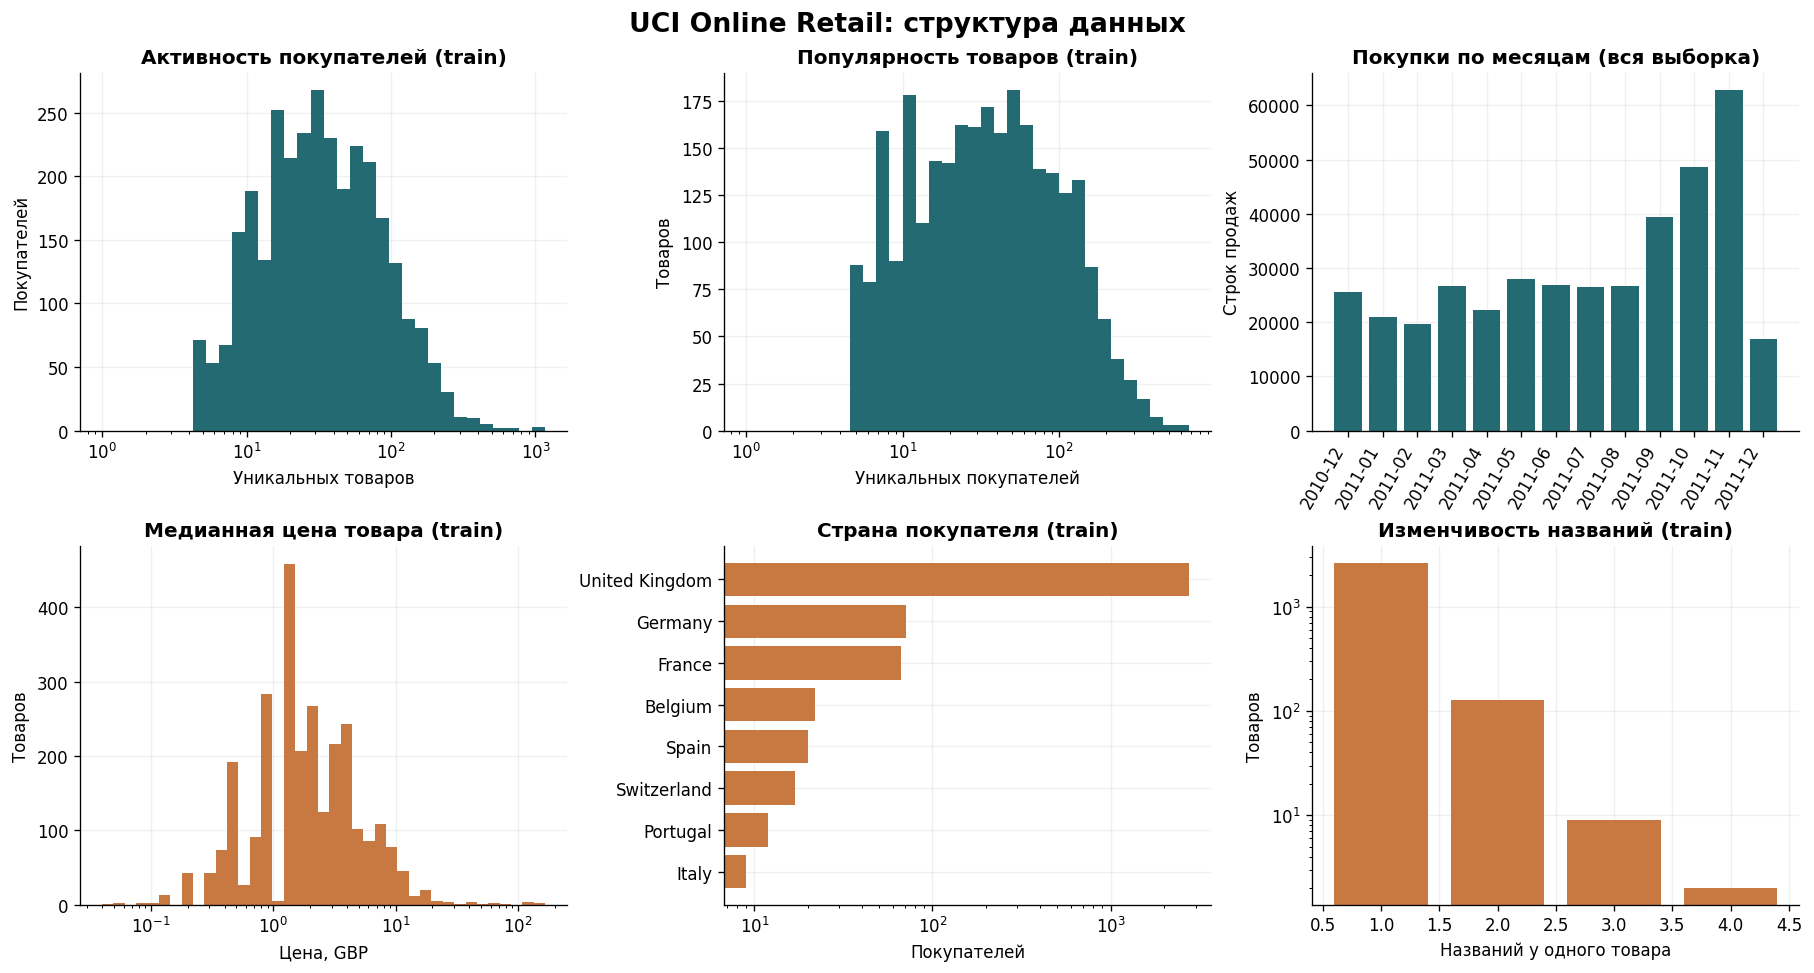

,товаров на покупателя,покупателей на товар
count,3076.000000,2761.000000
mean,52.160923,58.111916
std,66.323046,66.989331
min,5.000000,5.000000
25%,16.000000,14.000000
50%,32.000000,34.000000
75%,65.000000,75.000000
max,1164.000000,676.000000


In [3]:
def configure_plots():
    plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 150, "font.size": 10,
                         "axes.spines.top": False, "axes.spines.right": False,
                         "axes.titleweight": "bold", "axes.grid": True,
                         "grid.alpha": .18, "axes.axisbelow": True})


def plot_eda(clean, history):
    configure_plots()
    train = history
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
    activity = train.groupby("u").i.nunique()
    popularity = train.groupby("i").u.nunique()
    axes[0, 0].hist(activity, bins=np.geomspace(1, activity.max() + 1, 35), color="#246A73")
    axes[0, 0].set(xscale="log", title="Активность покупателей (train)", xlabel="Уникальных товаров", ylabel="Покупателей")
    axes[0, 1].hist(popularity, bins=np.geomspace(1, popularity.max() + 1, 35), color="#246A73")
    axes[0, 1].set(xscale="log", title="Популярность товаров (train)", xlabel="Уникальных покупателей", ylabel="Товаров")
    monthly = clean.groupby(clean.InvoiceDate.dt.to_period("M")).size()
    axes[0, 2].bar(np.arange(len(monthly)), monthly.values, color="#246A73")
    axes[0, 2].set_xticks(np.arange(len(monthly)), monthly.index.astype(str), rotation=60, ha="right")
    axes[0, 2].set(title="Покупки по месяцам (вся выборка)", ylabel="Строк продаж")
    price = train.groupby("i").UnitPrice.median()
    axes[1, 0].hist(price, bins=np.geomspace(price.min(), price.max() + 1, 40), color="#C87941")
    axes[1, 0].set(xscale="log", title="Медианная цена товара (train)", xlabel="Цена, GBP", ylabel="Товаров")
    countries = train.drop_duplicates("u", keep="last").Country.value_counts().head(8).sort_values()
    axes[1, 1].barh(countries.index, countries.values, color="#C87941")
    axes[1, 1].set(xscale="log", title="Страна покупателя (train)", xlabel="Покупателей")
    descriptions = train.groupby("i").Description.nunique().value_counts().sort_index()
    axes[1, 2].bar(descriptions.index, descriptions.values, color="#C87941")
    axes[1, 2].set(yscale="log", title="Изменчивость названий (train)", xlabel="Названий у одного товара", ylabel="Товаров")
    fig.suptitle("UCI Online Retail: структура данных", fontsize=16, weight="bold")
    return fig



eda_history = retained.loc[retained.InvoiceDate < VALIDATION_START]
plot_eda(clean, eda_history)
plt.show()
activity = eda_history.groupby('u').i.nunique()
popularity = eda_history.groupby('i').u.nunique()
display(pd.DataFrame({'товаров на покупателя': activity.describe(),
                      'покупателей на товар': popularity.describe()}))
print('Доля покупателей UK:', (eda_history.drop_duplicates('u', keep='last').Country == 'United Kingdom').mean())
print('Доля товаров с несколькими названиями:', (eda_history.groupby('i').Description.nunique() > 1).mean())


Распределения активности и популярности имеют длинный правый хвост; крупные заказы
могут быть оптовыми. Поэтому история в ItemKNN, EASE и FM бинарная, а сила взаимодействия
в iALS определяется числом разных счетов, а не количеством единиц товара.
Страна сильно смещена к UK, поэтому её различающая способность ограничена.
Изменяемость названий требует исторического снимка метаданных.


## 3. Протокол оценки

- **Train:** ранее 1 сентября 2011 года.
- **Validation:** с 1 сентября включительно до 15 октября 2011 года.
- **Test:** с 15 октября включительно по конец данных 9 декабря 2011 года.

Разбиение глобальное и временное. В каждом окне выдаётся один список рекомендаций
в начале окна. Validation использует историю train; после выбора настроек модели
переобучаются на train + validation для test.

Кандидаты — все товары зафиксированного исторического каталога за вычетом уже купленных
пользователем. Оценка выполняется по полному каталогу, без отрицательной подвыборки.
Пользователи и товары вне обучающего 5-core, включая новые ID, исключаются из оценки.
Повторно купленные известные товары также исключаются из множества релевантных.

Оцениваются пользователи, у которых есть хотя бы один новый релевантный товар
и не менее десяти кандидатов. Внутри каждого окна пользователи, кандидаты, разбиения,
правила исключения и релевантность одинаковы для всех моделей.
При равенстве оценок выбирается меньший фиксированный индекс товара.


In [4]:
train = retained.loc[retained.InvoiceDate < VALIDATION_START].copy()
validation = retained.loc[(retained.InvoiceDate >= VALIDATION_START) &
                          (retained.InvoiceDate < TEST_START)].copy()
test = retained.loc[retained.InvoiceDate >= TEST_START].copy()
assert train.InvoiceDate.max() < validation.InvoiceDate.min()
assert validation.InvoiceDate.max() < test.InvoiceDate.min()
assert set(train.InvoiceNo).isdisjoint(validation.InvoiceNo)
assert set(validation.InvoiceNo).isdisjoint(test.InvoiceNo)

audit = []
for name, start, stop in [('train', None, VALIDATION_START),
                          ('validation', VALIDATION_START, TEST_START),
                          ('test', TEST_START, None)]:
    mask = pd.Series(True, index=clean.index)
    if start is not None:
        mask &= clean.InvoiceDate >= start
    if stop is not None:
        mask &= clean.InvoiceDate < stop
    part = clean.loc[mask]
    keep = part.CustomerID.isin(umap) & part.StockCode.isin(imap)
    audit.append({'период': name, 'событий': len(part), 'сохранено': int(keep.sum()),
                  'исключено': int((~keep).sum()),
                  'пользователей вне train': part.loc[~part.CustomerID.isin(past.CustomerID), 'CustomerID'].nunique(),
                  'товаров вне train': part.loc[~part.StockCode.isin(past.StockCode), 'StockCode'].nunique()})
display(pd.DataFrame(audit))
K = 10
validation_known, _, _ = interaction_matrices(train, shape, VALIDATION_START)
history = pd.concat([train, validation], ignore_index=True)
test_known, _, _ = interaction_matrices(history, shape, TEST_START)
validation_protocol = prepare_evaluation(validation, validation_known, K)
test_protocol = prepare_evaluation(test, test_known, K)
display(pd.DataFrame([{'окно': 'validation', **validation_protocol['audit']},
                      {'окно': 'test', **test_protocol['audit']}]))


,период,событий,сохранено,исключено,пользователей вне train,товаров вне train
0,train,222940,220847,2093,0,0
1,validation,61663,41169,20494,469,168
2,test,106256,64645,41611,732,251


,окно,holdout_unique_pairs,repeat_pairs_excluded,novel_relevant_pairs,eligible_users,cohort_users,catalog_items,users_with_no_novel_positives,users_with_less_than_k_candidates
0,validation,37305,14747,22558,1122,3076,2761,1954,0
1,test,52540,21825,30715,1402,3076,2761,1674,0


## 4. Модели и подбор гиперпараметров

До поиска выбираем **NDCG@10** основной метрикой. Пространство поиска фиксировано ниже;
параметры выбираются только по validation. При равенстве метрик берём первый вариант.
На test параметры не подбираются.

### 4.1. ItemKNN (`models/item_knn.py`)

$X_{ui}=1$ при наличии покупки в истории. Косинусное сходство со сглаживанием:

$$s_{ij}=\frac{X_{:i}^{\mathsf T}X_{:j}}{\|X_{:i}\|\|X_{:j}\|}
\frac{n_{ij}}{n_{ij}+\gamma},\quad n_{ij}=X_{:i}^{\mathsf T}X_{:j},\quad s_{ii}=0.$$

Для каждого кандидата оставляем $L$ ближайших товаров, оценка $\hat r_{uj}=\sum_iX_{ui}s_{ij}$.
Сглаживание уменьшает влияние случайных совпадений у редких товаров.

### 4.2. iALS (`models/ials.py`)

$n_{ui}$ — число **разных счетов** с покупкой товара. Базовые предпочтения $p_{ui}=\mathbb I[n_{ui}>0]$,
confidence $c_{ui}=1+\alpha\ln(1+n_{ui})$; у ненаблюдавшихся пар $c_{ui}=1,p_{ui}=0$.

$$\min_{A,B}\sum_{u,i}c_{ui}(p_{ui}-a_u^{\mathsf T}b_i)^2+
\lambda(\|A\|_F^2+\|B\|_F^2).$$

При фиксированном $B$:
$$a_u=(B^{\mathsf T}C_uB+\lambda I)^{-1}B^{\mathsf T}C_up_u.$$

Решаем линейную систему через разложение Холецкого, не вычисляя обратную матрицу для каждой строки.
Обновления объектов симметричны. Ненаблюдавшиеся пары учтены через общий член $B^{\mathsf T}B$.

### 4.3. EASE (`models/ease.py`)

$$\min_W\|X-XW\|_F^2+\lambda\|W\|_F^2,\quad\operatorname{diag}(W)=0.$$
$$P=(X^{\mathsf T}X+\lambda I)^{-1},\quad W_{ij}=-P_{ij}/P_{jj}\;(i\ne j),\quad W_{ii}=0.$$

Оценки: $XW$. Реализация точная, без отсечения отрицательных весов. Память $O(|I|^2)$:
выбранный небольшой каталог делает такой эксперимент выполнимым.

### 4.4. FM с метаданными (`models/fm.py`)

$$\hat y(x)=w^{\mathsf T}x+\frac12\sum_{f=1}^d\left[
\left(\sum_jv_{jf}x_j\right)^2-\sum_jv_{jf}^2x_j^2\right].$$

Признаки: one-hot user ID, item ID, последняя известная страна пользователя;
категория медианной прошлой цены товара с фиксированными границами 1, 2, 5, 10, 20 GBP;
слова последнего известного названия. Слова длиной от 3 латинских букв, не менее чем в 3 товарах,
до 1000 по частоте с детерминированным разрешением равенств; вес каждого слова $1/\sqrt{m_i}$.
Названия могут меняться, поэтому не подставляется финальное описание из test.

Страна описывает покупательский рынок, цена — доступный ценовой сегмент, слова — материал, цвет и тип товара.
Сильное преобладание UK может ограничить полезность страны. Влияние метаданных проверяется сравнением с FM только на ID при тех же настройках.

Обучение на парах «купленный товар — случайный неизвестный товар», по одной отрицательной паре
на уникальную положительную пару в эпоху:
$$L=\frac1N\sum\log(1+\exp[-(\hat y_{ui^+}-\hat y_{ui^-})])+
\frac\lambda2(\|w\|^2+\|V\|_F^2).$$

Отрицательные товары выбираются равномерно из некупленных **в текущей обучающей истории**, без заглядывания
в будущую релевантность. Градиенты и Adam реализованы вручную. Свободный член не нужен: сокращается в BPR.
Дополнительно FM_ID_only использует только ID при тех же параметрах оптимизации.

### 4.5. iALS с собственным таргетом (`models/custom_ials.py`)

Давность $d_{ui}$ — число дней от последней покупки до момента рекомендации, $h$ — период полураспада:

$$p^*_{ui}=\begin{cases}
(1-\rho)+\rho(1-e^{-n_{ui}})2^{-d_{ui}/h},&n_{ui}>0,\\
0,&n_{ui}=0.
\end{cases}$$

Повторные покупки повышают оценку устойчивости интереса с насыщением, давние покупки ослабляют её.
Компонента $1-\rho$ не позволяет единичным или давним продажам исчезнуть из обучения.
Это проектная гипотеза для переноса свежих устойчивых интересов на новые товары, а не утверждение о новой
научной модели. При $\rho=0$ получается **точно базовый iALS**.

Confidence остаётся тем же $c_{ui}=1+\alpha\ln(1+n_{ui})$. Меняется именно $p_{ui}$ в правой части ALS.
Число факторов, регуляризация, число итераций и $\alpha$ фиксируются по лучшему базовому iALS;
на validation выбираются только $\rho,h$. Таким образом, финальная разница не объясняется заменой confidence
или другим размером модели. Повторные покупки полезны как обучающий сигнал, но тест по-прежнему измеряет
покупки **новых** товаров.


In [5]:
SEARCH = {'ItemKNN': [{'neighbors': 40, 'shrink': 10}, {'neighbors': 100, 'shrink': 10}, {'neighbors': 100, 'shrink': 50}], 'iALS': [{'factors': 32, 'alpha': 10, 'reg': 1.0, 'iterations': 15}, {'factors': 32, 'alpha': 40, 'reg': 1.0, 'iterations': 15}, {'factors': 64, 'alpha': 10, 'reg': 5.0, 'iterations': 15}, {'factors': 64, 'alpha': 40, 'reg': 5.0, 'iterations': 15}], 'EASE': [{'reg': 50}, {'reg': 200}, {'reg': 1000}], 'FM': [{'factors': 16, 'lr': 0.003, 'reg': 1e-05, 'epochs': 12, 'batch_size': 4096}, {'factors': 32, 'lr': 0.003, 'reg': 1e-05, 'epochs': 12, 'batch_size': 4096}, {'factors': 32, 'lr': 0.001, 'reg': 0.0001, 'epochs': 12, 'batch_size': 4096}], 'CustomiALS': [{'rho': 0.5, 'half_life': 30}, {'rho': 0.5, 'half_life': 90}, {'rho': 0.8, 'half_life': 30}, {'rho': 0.8, 'half_life': 90}]}
PRIMARY_METRIC = 'NDCG@10'
display(pd.DataFrame([{'модель': name, 'вариант': i + 1, 'параметры': json.dumps(params)}
                      for name, grid in SEARCH.items() for i, params in enumerate(grid)]))


,модель,вариант,параметры
0,ItemKNN,1,"{""neighbors"": 40, ""shrink"": 10}"
1,ItemKNN,2,"{""neighbors"": 100, ""shrink"": 10}"
2,ItemKNN,3,"{""neighbors"": 100, ""shrink"": 50}"
3,iALS,1,"{""factors"": 32, ""alpha"": 10, ""reg"": 1.0, ""iterations"": 15}"
4,iALS,2,"{""factors"": 32, ""alpha"": 40, ""reg"": 1.0, ""iterations"": 15}"
5,iALS,3,"{""factors"": 64, ""alpha"": 10, ""reg"": 5.0, ""iterations"": 15}"
6,iALS,4,"{""factors"": 64, ""alpha"": 40, ""reg"": 5.0, ""iterations"": 15}"
7,EASE,1,"{""reg"": 50}"
8,EASE,2,"{""reg"": 200}"
9,EASE,3,"{""reg"": 1000}"


In [6]:
bundle = history_bundle(train, shape, VALIDATION_START)
trials, selected = [], {}
for name in ['ItemKNN', 'iALS', 'EASE', 'FM', 'CustomiALS']:
    best_value = -np.inf
    for trial, custom_params in enumerate(SEARCH[name]):
        params = {**selected['iALS'], **custom_params} if name == 'CustomiALS' else custom_params.copy()
        model = train_model(name, params, bundle, SEED)
        metrics, _ = evaluate(model, validation_protocol)
        trials.append({'model': name, 'trial': trial + 1,
                       'NDCG@10': metrics['NDCG@10'], 'Recall@10': metrics['Recall@10'],
                       'params': json.dumps(params, sort_keys=True)})
        if metrics[PRIMARY_METRIC] > best_value:
            best_value = metrics[PRIMARY_METRIC]
            selected[name] = params.copy()
        del model
        gc.collect()
validation_results = pd.DataFrame(trials)
# Абляция метаданных: те же настройки FM, только признаки ID.
selected['FM_ID_only'] = selected['FM'].copy()
selected_json = json.dumps(selected, sort_keys=True)
display(validation_results)
display(pd.DataFrame([{'model': name, 'params': json.dumps(params, sort_keys=True)}
                      for name, params in selected.items()]))


,model,trial,NDCG@10,Recall@10,params
0,ItemKNN,1,0.108097,0.064333,"{""neighbors"": 40, ""shrink"": 10}"
1,ItemKNN,2,0.107360,0.060290,"{""neighbors"": 100, ""shrink"": 10}"
2,ItemKNN,3,0.107675,0.061241,"{""neighbors"": 100, ""shrink"": 50}"
3,iALS,1,0.084621,0.053658,"{""alpha"": 10, ""factors"": 32, ""iterations"": 15, ""reg"": 1.0}"
4,iALS,2,0.065179,0.042796,"{""alpha"": 40, ""factors"": 32, ""iterations"": 15, ""reg"": 1.0}"
5,iALS,3,0.088220,0.055249,"{""alpha"": 10, ""factors"": 64, ""iterations"": 15, ""reg"": 5.0}"
6,iALS,4,0.070611,0.044288,"{""alpha"": 40, ""factors"": 64, ""iterations"": 15, ""reg"": 5.0}"
7,EASE,1,0.103168,0.065596,"{""reg"": 50}"
8,EASE,2,0.110053,0.068268,"{""reg"": 200}"
9,EASE,3,0.110726,0.065681,"{""reg"": 1000}"


,model,params
0,ItemKNN,"{""neighbors"": 40, ""shrink"": 10}"
1,iALS,"{""alpha"": 10, ""factors"": 64, ""iterations"": 15, ""reg"": 5.0}"
2,EASE,"{""reg"": 1000}"
3,FM,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": 32, ""lr"": 0.003, ""reg"": 1e-05}"
4,CustomiALS,"{""alpha"": 10, ""factors"": 64, ""half_life"": 30, ""iterations"": 15, ""reg"": 5.0, ""rho"": 0.8}"
5,FM_ID_only,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": 32, ""lr"": 0.003, ""reg"": 1e-05}"


## 5. Финальное сравнение при K = 10

**NDCG@10**, поскольку порядок наиболее заметных рекомендаций важен.
Дополнительная: **Recall@10**, доля новых купленных товаров, найденных в десяти рекомендациях.
При бинарной релевантности $r_{u,j}$:

$$\mathrm{DCG@10}(u)=\sum_{j=1}^{10}\frac{r_{u,j}}{\log_2(j+1)},\qquad
\mathrm{NDCG@10}(u)=\frac{\mathrm{DCG@10}(u)}{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)},$$
$$\mathrm{Recall@10}(u)=\frac{|\mathrm{Top10}_u\cap R_u|}{|R_u|}.$$

Обе метрики усредняются по пользователям, без перевзвешивания по активности.
При многих будущих покупках Recall@10 ограничен сверху
значением $10/|R_u|$, поэтому абсолютные Recall и NDCG нельзя сравнивать друг с другом.

Используем выбранные настройки и переобучаем модели на train + validation.
Сравнение с FM только на ID проверяет влияние метаданных, а CustomiALS с iALS — влияние таргета.


,model,NDCG@10,Recall@10,users,params
2,EASE,0.098284,0.062564,1402,"{""reg"": 1000}"
4,CustomiALS,0.094447,0.057459,1402,"{""alpha"": 10, ""factors"": 64, ""half_life"": 30, ""iterations"": 15, ""reg"": 5.0, ""rho"": 0.8}"
0,ItemKNN,0.093604,0.057611,1402,"{""neighbors"": 40, ""shrink"": 10}"
1,iALS,0.089306,0.058001,1402,"{""alpha"": 10, ""factors"": 64, ""iterations"": 15, ""reg"": 5.0}"
3,FM,0.063071,0.036247,1402,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": 32, ""lr"": 0.003, ""reg"": 1e-05}"
5,FM_ID_only,0.062642,0.033909,1402,"{""batch_size"": 4096, ""epochs"": 12, ""factors"": 32, ""lr"": 0.003, ""reg"": 1e-05}"


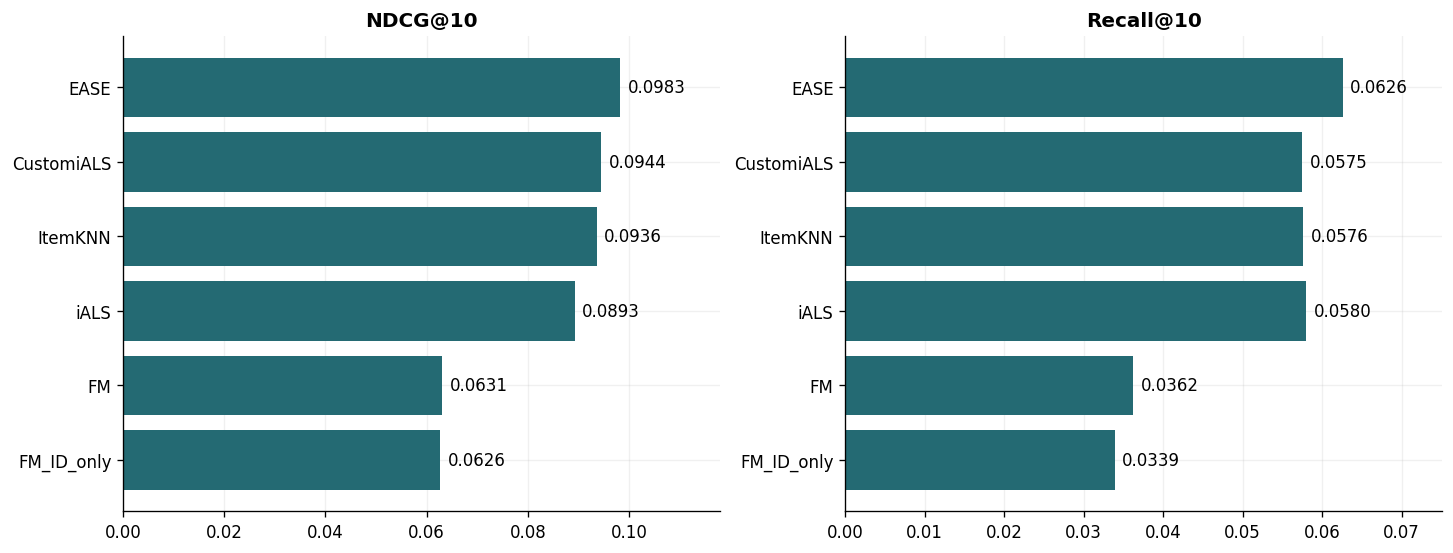

In [7]:
assert json.dumps(selected, sort_keys=True) == selected_json
final_bundle = history_bundle(history, shape, TEST_START)
rows = []
for name, params in selected.items():
    active = (history_bundle(history, shape, TEST_START, metadata=False)
              if name == 'FM_ID_only' else final_bundle)
    model = train_model(name, params, active, SEED)
    metrics, _ = evaluate(model, test_protocol)
    rows.append({'model': name, 'NDCG@10': metrics['NDCG@10'],
                 'Recall@10': metrics['Recall@10'], 'users': metrics['evaluated_users'],
                 'params': json.dumps(params, sort_keys=True)})
    del model
    gc.collect()
results = pd.DataFrame(rows).sort_values('NDCG@10', ascending=False)
display(results)

order = results.sort_values('NDCG@10')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, metric in zip(axes, ['NDCG@10', 'Recall@10']):
    ax.barh(order.model, order[metric], color='#246A73')
    for y, value in enumerate(order[metric]):
        ax.text(value + order[metric].max() * .015, y, f'{value:.4f}', va='center')
    ax.set(title=metric, xlim=(0, order[metric].max() * 1.2))
plt.show()


## 6. Выводы

Лучшая из пяти моделей — **EASE**: NDCG@10 = **0,09828**, Recall@10 = **0,06256**
при регуляризации 1000. На validation NDCG@10 вырос с 0,10317 при регуляризации 50
до 0,11073 при 1000. У ItemKNN выбраны 40 соседей и shrink = 10;
у iALS — 64 фактора, alpha = 10, регуляризация 5 и 15 итераций.
В проверенных парах настроек iALS значение alpha = 10 оказалось лучше alpha = 40.

**Собственный таргет:** при rho = 0,8 и периоде полураспада 30 дней NDCG@10 повысился
с 0,08931 до 0,09445, но Recall@10 снизился с 0,05800 до 0,05746.
Таргет улучшил порядок верхних рекомендаций в этом эксперименте, но не полноту.

**Метаданные FM:** при 32 факторах, шаге 0,003, регуляризации 0,00001,
12 эпохах и размере пакета 4096 NDCG@10 вырос с 0,06264 до 0,06307,
Recall@10 — с 0,03391 до 0,03625. Прирост небольшой, обе версии уступили остальным моделям.
Это сравнение при одинаковых настройках, без отдельной оптимизации FM только на ID.

**Ограничения:** один магазин и один временной срез с сезонным предрождественским test;
5-core смещает оценку к активным пользователям и товарам. Холодный старт не оценивается,
доступность товаров и показы неизвестны. Повторные покупки исключены из рекомендаций,
хотя важны для оптовых покупателей. Метаданные получены из прошлых чеков.
Один seed и небольшое пространство поиска не позволяют считать найденные настройки
оптимальными в целом или утверждать устойчивое преимущество метаданных и нового таргета.
